In [36]:
from luts import sky

In [37]:
from napari.viewer import Viewer
from AFMReader.jpk import load_jpk
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

In [38]:
from preprocessing import fit_plane_subtract, align_rows

In [43]:
path = Path("/Users/lmonari/Documents/afm/PART2/Box-4/2026_03_02_hepes_spin_filtration_flatten/save-2026.03.02-16.13.47.219.jpk")
image, pixel_to_nanometre_scaling_factor = load_jpk(file_path=path, channel="height_trace")

16:36:35 | INFO |jpk.py:jpk:load_jpk:213 | Loading image from : /Users/lmonari/Documents/afm/PART2/Box-4/2026_03_02_hepes_spin_filtration_flatten/save-2026.03.02-16.13.47.219.jpk
16:36:35 | INFO |jpk.py:jpk:_load_jpk_tags:274 | Configuration loaded from : /Users/lmonari/anaconda3/envs/afm/lib/python3.12/site-packages/AFMReader/default_config.yaml
16:36:35 | INFO |jpk.py:jpk:load_jpk:251 | [save-2026.03.02-16.13.47.219] : Extracted image.


TypeError: unhashable type: 'Colormap'

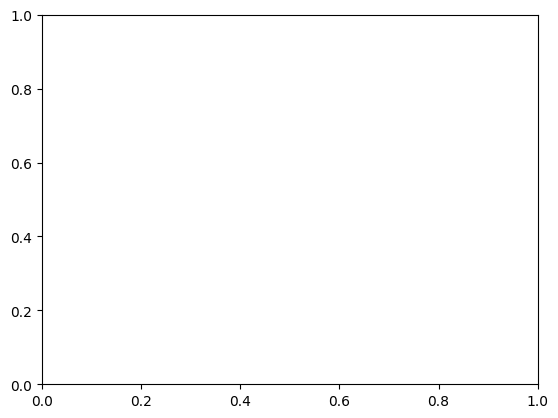

In [ ]:
image = fit_plane_subtract(image)[0]
image = align_rows(image)
plt.imshow(image, cmap='gray')

In [22]:
viewer = Viewer()

In [23]:
viewer.add_image(image, colormap=sky)

<Image layer 'image' at 0x10ee623f0>

In [24]:
image = fit_plane_subtract(image)[0]

In [25]:
viewer.add_image(image, colormap=sky)

<Image layer 'image [1]' at 0x10ee8f920>

In [26]:
image = align_rows(image, method="polynomial", poly_degree=5)[0]
viewer.add_image(image, colormap=sky)

<Image layer 'image [2]' at 0x10e39ff50>

(array([1.0000e+00, 2.0000e+00, 2.0000e+00, 1.0000e+00, 7.0000e+00,
        1.5000e+01, 1.8000e+01, 2.8000e+01, 4.3000e+01, 7.0000e+01,
        1.2000e+02, 1.6800e+02, 2.1400e+02, 2.6800e+02, 3.6300e+02,
        4.7800e+02, 4.8500e+02, 5.4300e+02, 6.3200e+02, 7.1600e+02,
        7.4800e+02, 8.7900e+02, 9.7900e+02, 1.2960e+03, 1.7770e+03,
        2.5410e+03, 3.6840e+03, 5.3550e+03, 7.4900e+03, 1.0833e+04,
        1.4025e+04, 1.7760e+04, 2.1097e+04, 2.3540e+04, 2.4835e+04,
        2.3949e+04, 2.1478e+04, 1.8630e+04, 1.5422e+04, 1.1678e+04,
        8.7140e+03, 5.7920e+03, 3.7650e+03, 2.3060e+03, 1.4480e+03,
        9.0300e+02, 6.2900e+02, 4.2400e+02, 3.1000e+02, 2.4100e+02,
        2.0400e+02, 1.5900e+02, 1.6200e+02, 1.3800e+02, 1.2000e+02,
        1.2500e+02, 1.0800e+02, 1.2100e+02, 1.3000e+02, 1.3100e+02,
        1.5000e+02, 1.9000e+02, 1.5300e+02, 1.9700e+02, 1.9400e+02,
        2.1300e+02, 2.3800e+02, 2.7700e+02, 2.7100e+02, 2.9200e+02,
        2.4900e+02, 2.6600e+02, 2.8100e+02, 2.14

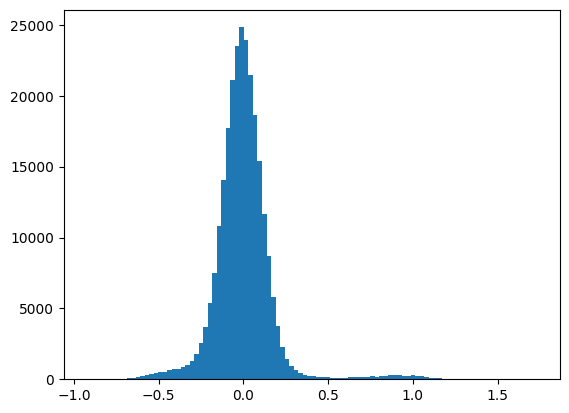

In [27]:
plt.hist(image.flatten(), bins=100)

In [28]:
mask = image>0

In [29]:
viewer.add_labels(mask.astype(int), name="mask")

<Labels layer 'mask' at 0x1107378c0>

In [30]:
image = align_rows(image, mask=mask)[0]

In [31]:
viewer.add_image(image, colormap=sky)

<Image layer 'image [3]' at 0x10ed2f440>

In [32]:
from skimage import exposure
def rescale_intensity(img):
    # rescale for better contrast (robust)
    p_low, p_high = np.percentile(img, (1, 99))
    if p_high > p_low:
        img = exposure.rescale_intensity(img, in_range=(p_low, p_high))
    return img

In [33]:
img_rescaled = rescale_intensity(image)

In [34]:
viewer.add_image(img_rescaled, colormap=sky)

<Image layer 'img_rescaled' at 0x10ed2f7d0>

In [ ]:
viewer.

ImportError: An error occured when importing Qt dependencies.  Cannot show napari window.  See cause above